In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

In [4]:
import pandas as pd

data = {
    "Weight": [
        45, 50, 55, 60, 65, 70, 75, 80, 85, 90,
        48, 53, 58, 63, 68, 73, 78, 83, 88, 93,
        47, 52, 57, 62, 67, 72, 77, 82, 87, 92
    ],
    "Height": [
        150, 155, 160, 165, 170, 175, 180, 185, 190, 195,
        152, 157, 162, 167, 172, 177, 182, 187, 192, 197,
        151, 156, 161, 166, 171, 176, 181, 186, 191, 196
    ]
}

df = pd.DataFrame(data)

print(df)

    Weight  Height
0       45     150
1       50     155
2       55     160
3       60     165
4       65     170
5       70     175
6       75     180
7       80     185
8       85     190
9       90     195
10      48     152
11      53     157
12      58     162
13      63     167
14      68     172
15      73     177
16      78     182
17      83     187
18      88     192
19      93     197
20      47     151
21      52     156
22      57     161
23      62     166
24      67     171
25      72     176
26      77     181
27      82     186
28      87     191
29      92     196


In [5]:
df.to_csv("weight_height.csv", index=False)

In [6]:
df = pd.read_csv("weight_height.csv")

In [7]:
df.head()

,Weight,Height
0,45,150
1,50,155
2,55,160
3,60,165
4,65,170


Text(0, 0.5, 'Height')

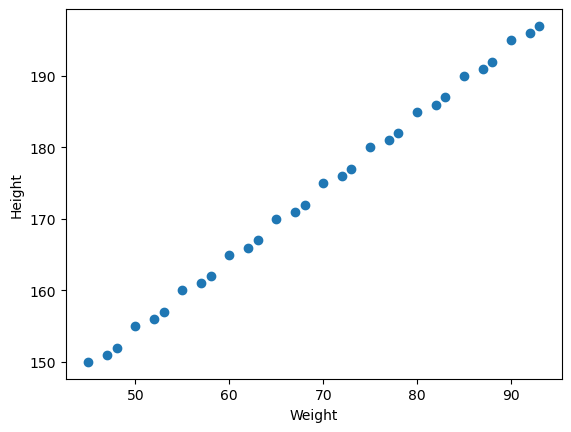

In [8]:
##scatter plot
plt.scatter(df["Weight"],df["Height"])
plt.xlabel("Weight")
plt.ylabel("Height")


In [11]:
## correlation

df.corr()

,Weight,Height
Weight,1.000000,0.999466
Height,0.999466,1.000000


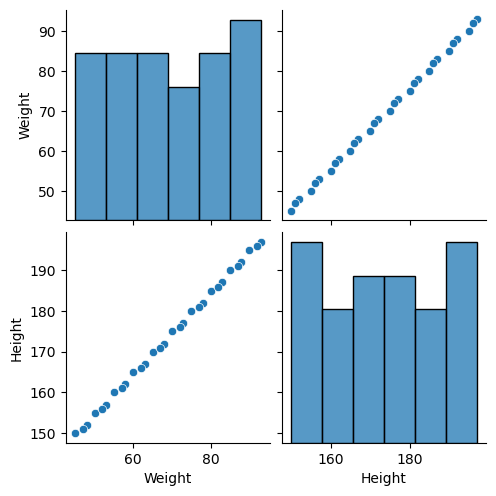

In [14]:
## seaborn for visulization
import seaborn as sns 
sns.pairplot(df)


In [20]:
## independent and dependent features 

X = df[["Weight"]] ### Independent features should be dataFram or 2 dimensional array 
y = df['Height']  ### this variable can be in array or in 1d array 


In [23]:
## Train test split 

from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.25, random_state = 42) ##random_state is a parameter used to control the randomness of dataset splitting , Agar random_state nahi doge, toh har execution mein generally naya random split milega.


In [27]:
## Standardization 

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

C:\Users\yogen\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [31]:
##apply simple linear regression 

from sklearn.linear_model import LinearRegression 
regression = LinearRegression()

In [33]:
regression.fit(X_train , y_train)

LinearRegression()

In [39]:
print("Coefficient of slop" , regression.coef_)
print("Intercept" , regression.intercept_)

Coefficient of slop [14.29061032]
Intercept 170.0909090909091


Intercept 170.0909090909091


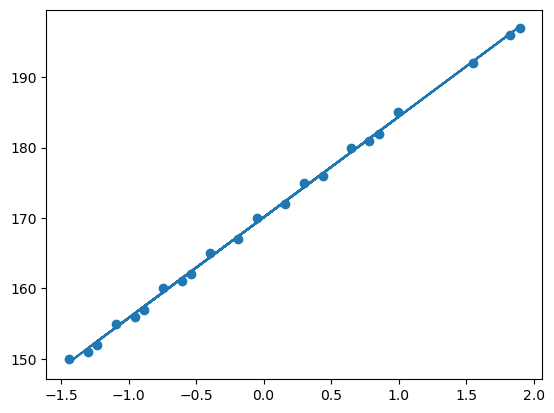

In [43]:
## plot best fit line with respect to training data 
plt.scatter(X_train , y_train)
plt.plot(X_train , regression.predict(X_train))

### prediction of test data 
1. predict height output = Intercept+coef(weight)
2. y_pred_test = 170.09 +  14.29(X_test)

In [44]:
## prediction for test data 
y_pred = regression.predict(X_test)

In [46]:
## Performance matrix 

from sklearn.metrics import mean_absolute_error , mean_squared_error 


In [47]:
mse = mean_squared_error(y_test , y_pred)
mae = mean_absolute_error(y_test , y_pred)
rmse = np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

1249613.887305963
1110.8151457767285
1117.8613005672767


In [48]:
from sklearn.metrics import r2_score 


In [49]:
score = r2_score(y_test , y_pred)
print(score)

-13312.682168733418


In [54]:
##OLS linear regression 
import statsmodels.api as sm 
model = sm.OLS(X_train , y_train).fit()

In [55]:
prediction = model.predict(X_test)
print(prediction)

[0.0402202  0.03580578 0.03041039 0.04071069 0.04169167 0.04414412
 0.04267265 0.03286284]


In [56]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                      y   R-squared (uncentered):                   0.007
Model:                            OLS   Adj. R-squared (uncentered):             -0.040
Method:                 Least Squares   F-statistic:                             0.1482
Date:                Sun, 01 Nov 2026   Prob (F-statistic):                       0.704
Time:                        01:01:40   Log-Likelihood:                         -31.139
No. Observations:                  22   AIC:                                      64.28
Df Residuals:                      21   BIC:                                      65.37
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [61]:
## prediction For new data 

regression.predict(scaler.transform([[75]]))

array([1241.88668335])

In [2]:
print("X_train shape:", X_train.shape)

print("Y_train shape:", y_train.shape)

print("Scaler mean:", scaler.mean_)

print("Regression coefficient:", regression.coef_)
print("Regression intercept:", regression.intercept_)

NameError: name 'X_train' is not defined